# Predicting German Credit Risk (logit regression&xgboost)
### Welcome to the kernel of a starter in kaggle!    
### If you like it, please **vote up**!

## content
1. statistical discription
2. data exploring
3. data processing
4. modeling


### 1. statistical discription
#### 1.1 data loading     
##### 1) Choose data with y-value from data set "german_credit_data_with_risk".
##### 2) Then show the first six row of the table, remove the first column, which is the id of sample.

In [1]:
####statistical discription####
#1.1data loading
dat = read.csv("../input/german-credit-data-with-risk/german_credit_data.csv")

head(dat)            #watch first 6 row of the data
dat = dat[,-1]       #remove the first column

X,Age,Sex,Job,Housing,Saving.accounts,Checking.account,Credit.amount,Duration,Purpose,Risk
0,67,male,2,own,NA,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,NA,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad
5,35,male,1,free,NA,NA,9055,36,education,good


#### 1.2 know more about the data

##### 1) Use summary to know that there are four numerical variables, while others are all categorical variables.
##### 2) 'checking.account' and 'saving.account' have missing values which take up 39.4% and 18.3%.
##### 3) Noticing that y-value is unbalanced, so we msy need group sampling. 
##### 4) Next devide these samples by y-value.


      Age            Sex           Job        Housing      Saving.accounts
 Min.   :19.00   female:310   Min.   :0.000   free:108   little    :603   
 1st Qu.:27.00   male  :690   1st Qu.:2.000   own :713   moderate  :103   
 Median :33.00                Median :2.000   rent:179   quite rich: 63   
 Mean   :35.55                Mean   :1.904              rich      : 48   
 3rd Qu.:42.00                3rd Qu.:2.000              NA's      :183   
 Max.   :75.00                Max.   :3.000                               
                                                                          
 Checking.account Credit.amount      Duration                   Purpose   
 little  :274     Min.   :  250   Min.   : 4.0   car                :337  
 moderate:269     1st Qu.: 1366   1st Qu.:12.0   radio/TV           :280  
 rich    : 63     Median : 2320   Median :18.0   furniture/equipment:181  
 NA's    :394     Mean   : 3271   Mean   :20.9   business           : 97  
                  3rd Qu.

Age              Sex              Job          Housing 
             0.0              0.0              0.0              0.0 
 Saving.accounts Checking.account    Credit.amount         Duration 
            18.3             39.4              0.0              0.0 
         Purpose             Risk 
             0.0              0.0

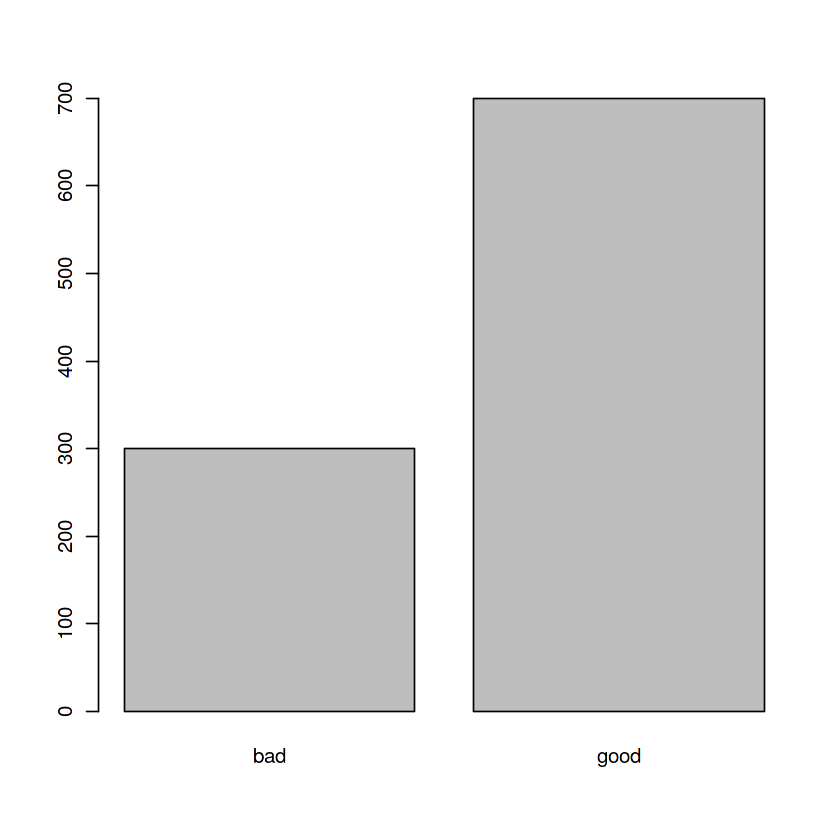

In [2]:
#know more about the data
#summary of the data
summary(dat)

#check the rate of missing values
miss = function(x){sum(is.na(x))/length(x)*100}
apply(dat,2,miss)

#pay attention to the unbalanced y-value
plot(dat[,10])

#devide them by y-value
good = dat[which(dat[,10]=="good"),]
bad = dat[which(dat[,10]=="bad"),]

### 2.data exploring
#### 2.1 age & housing
##### Draw histogram of age and housing respectively in t"y-value good", "y-value bad", "all".

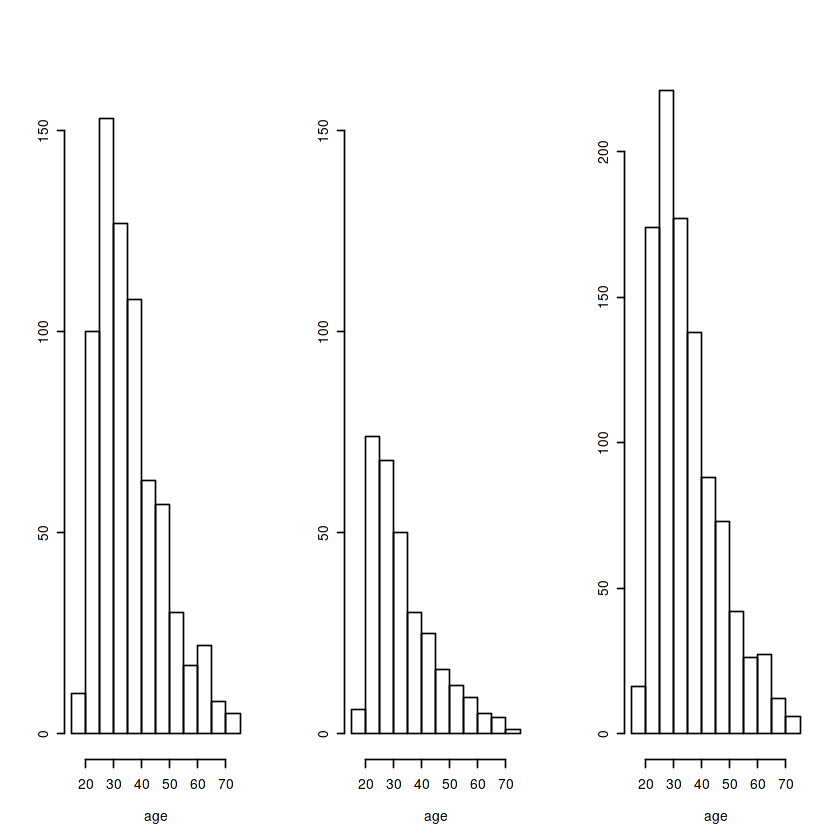

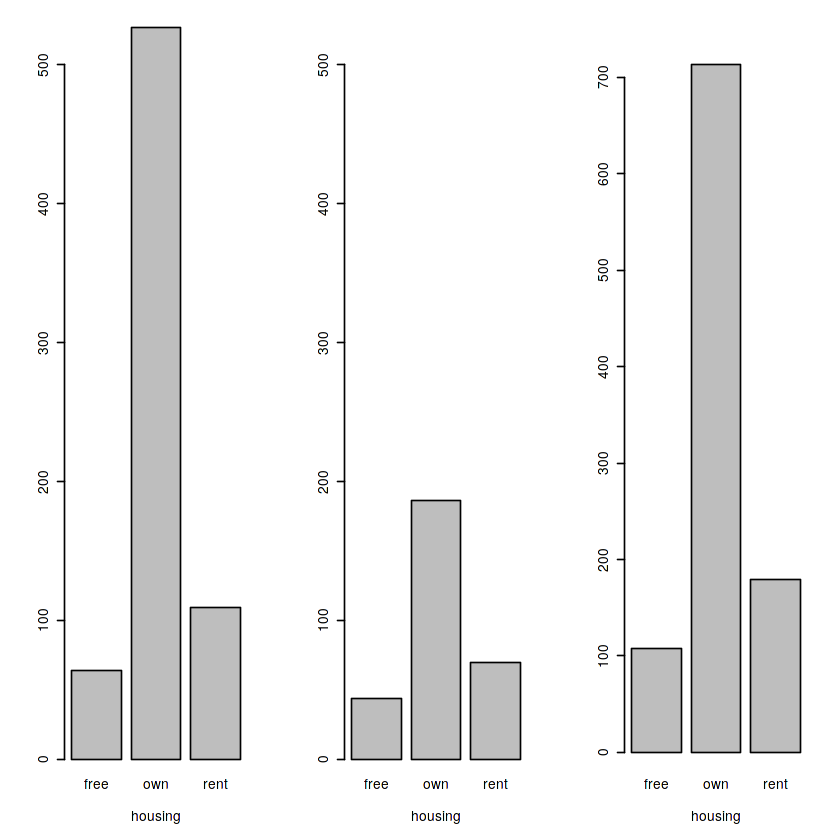

In [3]:
####data exploring####
# 2.1 age & housing
#age
#win.graph(width = 8,height = 2.5)
par(mfrow=c(1,3))
hist(good[,1],xlab="age",ylab="",main="",ylim=c(0,160))
hist(bad[,1],xlab="age",ylab="",main="",ylim=c(0,160))
hist(dat[,1],xlab="age",ylab="",main="")

#housing
plot(good[,4],xlab="housing",ylab="",main="",ylim=c(0,500))
plot(bad[,4],xlab="housing",ylab="",main="",ylim=c(0,500))
plot(dat[,4],xlab="housing",ylab="",main="")

##### 1) The distribution diagrams of "good" and "all" groups are identical.
##### 2) Variable "age" has right-skewed distribution.
##### 3) People who own a house are more likely in "good credit" group. 

#### 2.2 credit amount & duration
##### Draw scatter plot of them in "y-value good"(circle shape), "y-value bad"(cross shape).

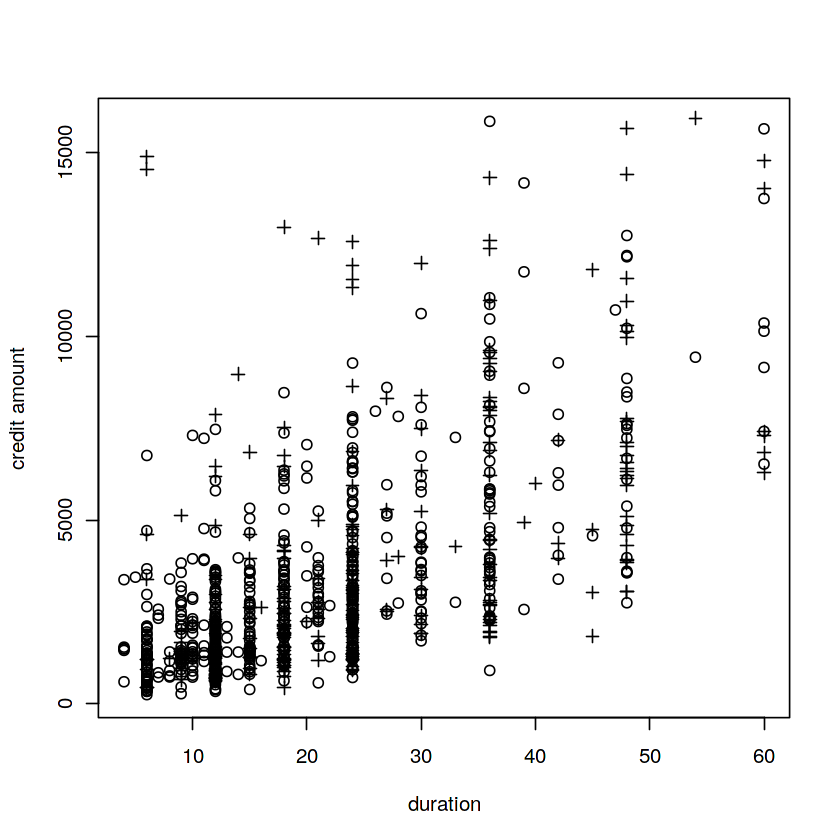

In [4]:
#2.2 credit amount&duration
plot(y=good[,7],x=good[,8],pch=1,
     xlab="duration",ylab="credit amount",main="")
points(y=bad[,7],x=bad[,8],pch=3,
     xlab="duration",ylab="credit amount",main="")

##### 1) In general, the number of short term loan is more than that of mid&long term loan, however the amount of the latter is more dispersed.
##### 2) The defaults usually appears at a greater amount loan when the duration remains unchanged. Noticed that there is a gap between the top cross shape(s) and the following shapes in a column, it is clear that the shorter the duration, the greater the gap.
### 3. data processing   
##### Handle categorical variables: sex, housing, saving, checking, purpose and risk.
##### Then make a correlation plot.

corrplot 0.84 loaded


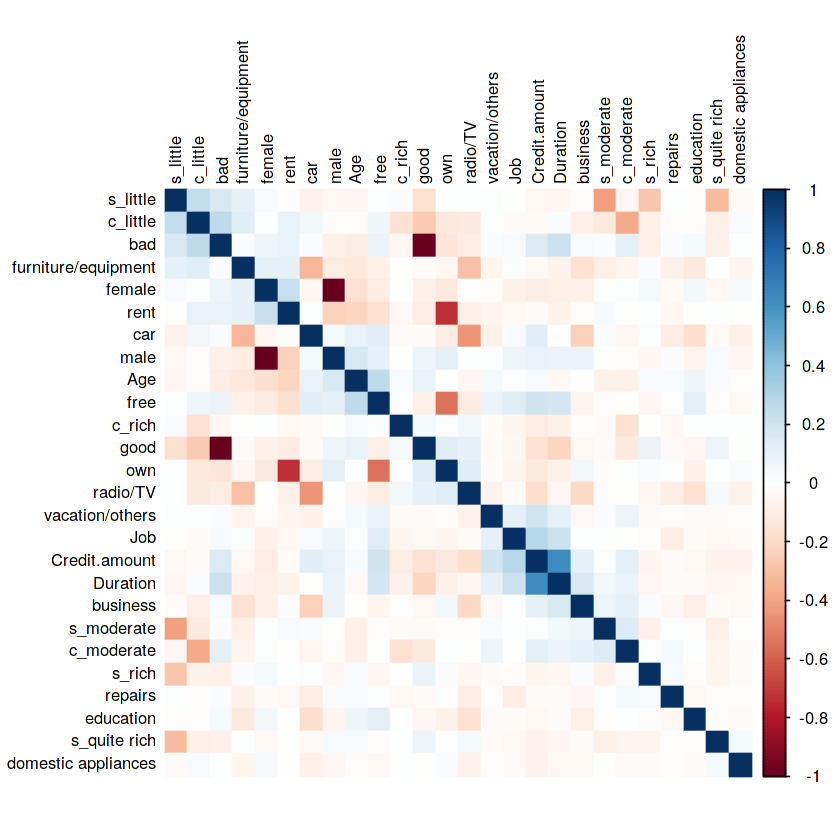

In [5]:
####data processing####
#handle categorical variables
library(nnet)
sex = class.ind(dat[,2]) 
housing = class.ind(dat[,4]) 
saving = class.ind(dat[,5])
colnames(saving) = c("s_little","s_moderate","s_quite rich","s_rich")
checking = class.ind(dat[,6]) 
colnames(checking) = c("c_little","c_moderate","c_rich")
purpose = class.ind(dat[,9]) 
risk = class.ind(dat[,10])

#correlation plot
datn = dat[,c(-2,-4,-5,-6,-9,-10)]
newdat = cbind(datn,sex,housing,saving,checking,purpose,risk)
mycor = cor(newdat)

library(corrplot)
par(mfrow = c(1,1))
corrplot(mycor,tl.col="black",method="color",shade.lwd = 0.1,tl.cex=0.8,order="hclust")

##### From the plot above, it is clear that "saving.account little", "checking.account little", "duration", "credit.amount" have weak positive correlation to "bad".
##### "checking.account little", "duration" have relatively strong positive correlation.
### 4. modeling
#### 4.1 split data by group sampling 
##### Choose 70% as sampling ratio.

In [6]:
#4.1 split data by group sampling
newdat = newdat[,-25]
newdat = as.matrix(newdat[order(newdat$good), ])
siz = c(300,700)
n = round(0.7*siz)

library(sampling)
tr = strata(newdat, stratanames='good', size=n, method="srswor")
train = newdat[tr$ID_unit,] 
test = newdat[-tr$ID_unit,] 
xtr = train[,1:24]
ytr = train[,25] 
xte = test[,1:24]
yte = test[,25]

#write.table(train, file ="train data.csv", sep =",")
#write.table(test, file ="test data.csv", sep =",")


#### 4.2 logistic regression
##### Notice: the critical values are different in glm-fitted.values and predict results!

In [7]:
#4.2 logistic regression
glm = glm(good~.,data=as.data.frame(train),family=binomial("logit"))

logit.step = step(glm, direction = c("both"))

glm1 = glm(good~s_little+c_little+c_moderate+Duration+female+own,
           data=as.data.frame(train),family=binomial("logit"))

#computing classification rate in training set
pyltr = glm1$fitted.values
yltr = rep(0,length(pyltr))
for(i in 1:length(pyltr)){
  if(pyltr[i]<=0.5){yltr[i]=0}
  else{yltr[i]=1}
}
train_result1 = table(yltr,ytr)
rate1 = (train_result1[1,1]+train_result1[2,2])/sum(train_result1)

#computing classification rate in testing set
y_pred = predict(glm1, as.data.frame(xte))
y_tran = rep(0,length(y_pred))
for(i in 1:length(y_pred)){
  if(y_pred[i]<=0){y_tran[i]=0}
  else{y_tran[i]=1}
}
test_result1 = table(y_tran,yte)
rate2 = (test_result1[1,1]+test_result1[2,2])/sum(test_result1)

Start:  AIC=744.68
good ~ Age + Job + Credit.amount + Duration + female + male + 
    free + own + rent + s_little + s_moderate + `s_quite rich` + 
    s_rich + c_little + c_moderate + c_rich + business + car + 
    `domestic appliances` + education + `furniture/equipment` + 
    `radio/TV` + repairs + `vacation/others`


Step:  AIC=744.68
good ~ Age + Job + Credit.amount + Duration + female + male + 
    free + own + rent + s_little + s_moderate + `s_quite rich` + 
    s_rich + c_little + c_moderate + c_rich + business + car + 
    `domestic appliances` + education + `furniture/equipment` + 
    `radio/TV` + repairs


Step:  AIC=744.68
good ~ Age + Job + Credit.amount + Duration + female + male + 
    free + own + s_little + s_moderate + `s_quite rich` + s_rich + 
    c_little + c_moderate + c_rich + business + car + `domestic appliances` + 
    education + `furniture/equipment` + `radio/TV` + repairs


Step:  AIC=744.68
good ~ Age + Job + Credit.amount + Duration + female + free + 
 

#### 4.3 logistic regression

In [8]:
####xgboost####

library(xgboost)
xgb = xgboost(data = xtr, 
               label = ytr, 
               eta = 0.1,
               max_depth = 5, 
               gamma = 0,
               objective = "binary:logistic",
               nrounds = 15, 
               subsample = 0.8,
               colsample_bytree = 0.8,
               seed = 1,
               eval_metric = "error"
)

#computing classification rate in training set
y_pred = predict(xgb, xtr)
y_train = rep(0,length(y_pred))
for(i in 1:length(y_pred)){
  if(y_pred[i]<=0.5){y_train[i]=0}
  else{y_train[i]=1}
}
test_result3 = table(y_train,ytr)
rate3 = (test_result3[1,1]+test_result3[2,2])/sum(test_result3)

#computing classification rate in testing set
y_pred = predict(xgb, xte)
y_test = rep(0,length(y_pred))
for(i in 1:length(y_pred)){
  if(y_pred[i]<=0.5){y_test[i]=0}
  else{y_test[i]=1}
}
test_result4 = table(y_test,yte)
rate4 = (test_result4[1,1]+test_result4[2,2])/sum(test_result4)


[1]	train-error:0.214286 
[2]	train-error:0.208571 
[3]	train-error:0.185714 
[4]	train-error:0.190000 
[5]	train-error:0.184286 
[6]	train-error:0.177143 
[7]	train-error:0.180000 
[8]	train-error:0.181429 
[9]	train-error:0.177143 
[10]	train-error:0.178571 
[11]	train-error:0.167143 
[12]	train-error:0.164286 
[13]	train-error:0.165714 
[14]	train-error:0.161429 
[15]	train-error:0.158571 


#### 4.4 results 

In [9]:
paste("classification rate in training set via logit regression is", round(rate1,2))
paste("classification rate in testing set via logit regression is", round(rate2,2))
paste("classification rate in training set via xgboost is", round(rate3,2))
paste("classification rate in testing set via xgboost is", round(rate4,2))

[1] "classification rate in training set via logit regression is 0.74"

[1] "classification rate in testing set via logit regression is 0.74"

[1] "classification rate in training set via xgboost is 0.84"

[1] "classification rate in testing set via xgboost is 0.76"